In [1]:
!pip install nltk scikit-learn pandas matplotlib seaborn

In [2]:
import nltk

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

Import libraries and create text data

In [3]:
import nltk
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.tokenize import word_tokenize
from nltk.corpus import wordnet
from nltk.corpus import stopwords

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

documents = [
    "I love natural language processing",
    "Natural language processing is interesting",
    "I love machine learning",
    "Machine learning is part of artificial intelligence"
]

print("Documents:")
for doc in documents:
    print(doc)

Documents:
I love natural language processing
Natural language processing is interesting
I love machine learning
Machine learning is part of artificial intelligence


Lexical Semantics (Synonyms and Antonyms)

In [4]:
word = "happy"

synonyms = set()
antonyms = set()

for syn in wordnet.synsets(word):
    for lemma in syn.lemmas():

        synonyms.add(lemma.name())

        if lemma.antonyms():
            antonyms.add(lemma.antonyms()[0].name())

print("Word:", word)

print("\nSynonyms:")
print(synonyms)

print("\nAntonyms:")
print(antonyms)

Word: happy

Synonyms:
{'happy', 'glad', 'well-chosen', 'felicitous'}

Antonyms:
{'unhappy'}


Words and Vectors

In [5]:
words = ["apple", "banana", "mango", "orange"]

word_vectors = {}

for i, word in enumerate(words):
    vector = [0] * len(words)
    vector[i] = 1
    word_vectors[word] = vector

for word, vector in word_vectors.items():
    print(word, ":", vector)

apple : [1, 0, 0, 0]
banana : [0, 1, 0, 0]
mango : [0, 0, 1, 0]
orange : [0, 0, 0, 1]


Bag of Words (BoW)

In [6]:
vectorizer = CountVectorizer()

bow_matrix = vectorizer.fit_transform(documents)

bow_df = pd.DataFrame(
    bow_matrix.toarray(),
    columns=vectorizer.get_feature_names_out()
)

print("Bag of Words:")
display(bow_df)

Bag of Words:


,artificial,intelligence,interesting,is,language,learning,love,machine,natural,of,part,processing
0,0,0,0,0,1,0,1,0,1,0,0,1
1,0,0,1,1,1,0,0,0,1,0,0,1
2,0,0,0,0,0,1,1,1,0,0,0,0
3,1,1,0,1,0,1,0,1,0,1,1,0


Cosine Similarity

In [7]:
similarity_matrix = cosine_similarity(bow_matrix)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=["Doc 1", "Doc 2", "Doc 3", "Doc 4"],
    columns=["Doc 1", "Doc 2", "Doc 3", "Doc 4"]
)

print("Cosine Similarity:")
display(similarity_df)

Cosine Similarity:


,Doc 1,Doc 2,Doc 3,Doc 4
Doc 1,1.000000,0.670820,0.288675,0.000000
Doc 2,0.670820,1.000000,0.000000,0.169031
Doc 3,0.288675,0.000000,1.000000,0.436436
Doc 4,0.000000,0.169031,0.436436,1.000000


TF-IDF

In [8]:
tfidf_vectorizer = TfidfVectorizer()

tfidf_matrix = tfidf_vectorizer.fit_transform(documents)

tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=tfidf_vectorizer.get_feature_names_out()
)

print("TF-IDF Matrix:")
display(tfidf_df.round(3))

TF-IDF Matrix:


,artificial,intelligence,interesting,is,language,learning,love,machine,natural,of,part,processing
0,0.000,0.000,0.000,0.000,0.500,0.000,0.500,0.000,0.500,0.000,0.000,0.500
1,0.000,0.000,0.536,0.422,0.422,0.000,0.000,0.000,0.422,0.000,0.000,0.422
2,0.000,0.000,0.000,0.000,0.000,0.577,0.577,0.577,0.000,0.000,0.000,0.000
3,0.413,0.413,0.000,0.326,0.000,0.326,0.000,0.326,0.000,0.413,0.413,0.000


TF-IDF Visualization

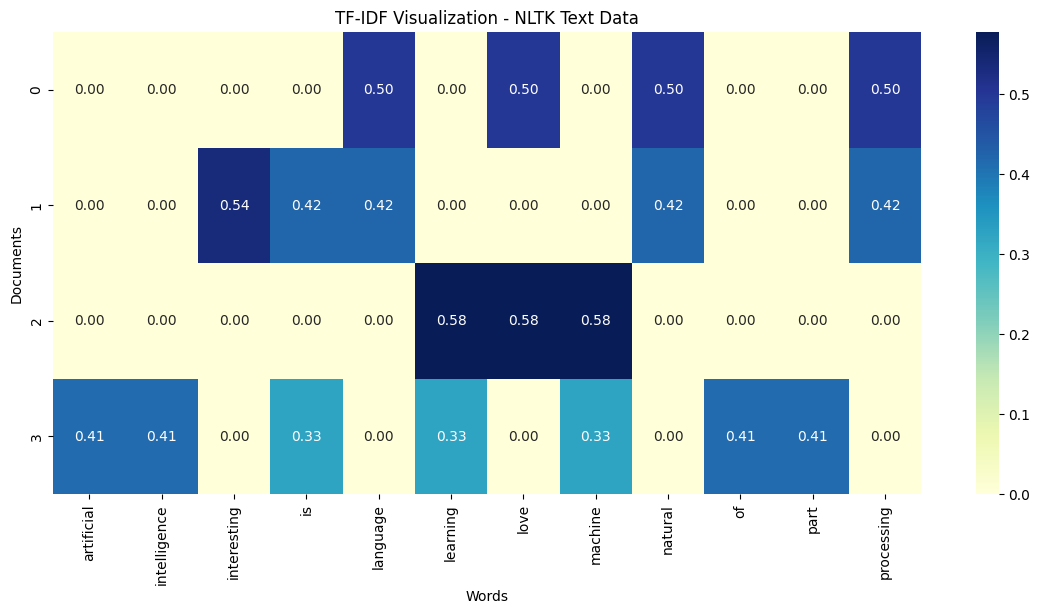

In [9]:
plt.figure(figsize=(14, 6))

sns.heatmap(
    tfidf_df,
    annot=True,
    cmap="YlGnBu",
    fmt=".2f"
)

plt.title("TF-IDF Visualization - NLTK Text Data")
plt.xlabel("Words")
plt.ylabel("Documents")

plt.show()